In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
activity = pd.read_csv("Dataset/Activity.csv")
sleep = pd.read_csv("Dataset/Sleep.csv")
physiology = pd.read_csv("Dataset/Physiology.csv")
labels = pd.read_csv("Dataset/Labels.csv")
demographics = pd.read_csv("Dataset/Demographics.csv")

Participants needed to meet certain requirements to be able to participate within the study, which was be 50 years or older and be medically disagnosed with dementia or have cognitive impairments, and have been either treated by the Old Age Psychiatry or are currently recieving treatment. For each participant, data was collected for around 50 days. 

In [3]:
print(activity.dtypes)

patient_id       object
location_name    object
date             object
dtype: object


In [4]:
activity.shape

(1030559, 3)

The activity table has 1,030,559 rows and 3 columns. All 56 participants were having movement data collected.

In the activity table, data is collected to track movement within different locations of the home. The data was collected via PIR sensors installed in the hallway and living room, movement sensors installed on the kitchen, bedroom, and bathroom doors, and a door sensor installed in the main entrance of home. The frequency in which data was collected was continuous from multiple locations as sensors were placed in different areas of the home of particpant. It includes three variables: patient_id, location_name, and date. Patient_id is a unique identifier of the participants within the study (56 values), location_name has 8 unique values which represent the location where movement is done within the home (Hallway, Lounge, Fridge, Back Door, Bedroom, Kitchen, Fridge Door, Bathroom, Front Door, Dining Room), and date which represents the date when this movement was recorded. A limitation within the activity data includes that the sensors recorded data of everyone within the home (such as caregiver, partner, etc.) and was not strictly limited to PLWD.

In [5]:
print(sleep.dtypes)

patient_id           object
date                 object
state                object
heart_rate          float64
respiratory_rate    float64
snoring                bool
dtype: object


In [6]:
sleep.shape

(461423, 6)

The sleep table has 461,423 rows and 6 columns. The sleep data of only 17 participants was collected.

In the sleep table, data is collected to be able to monitor the participants sleeping behavior and habits. An under-the-mattress sleep mat was used to record the data. Data will be collected as long as participant is sleeping on top of the mattress where device is located. The frequency in which this data was collected was every minute. It includes 6 varaibles: patient_id which uniquely identifies the participant, date which represents the date when the participant was sleeping, state represents the current state of participants sleep and could be one of 4 values (LIGHT, AWAKE, DEEP, REM), heart_rate represents participants heart rate while sleeping, respitory rate represents particpants respitory rate while sleeping, and snoring (either be true or false) represents if participant was snoring during sleep. The under-the-matress sleep mat records heart_rate, respitory_rate, and snoring, however, state is derived based on the measurements collected from the under-the-matress sleep mat to categorize the participants sleep. 

In [7]:
print(physiology.dtypes)

patient_id      object
date            object
device_type     object
value          float64
unit            object
dtype: object


In [8]:
physiology.shape

(17679, 5)

The shape of the physiology table is that it contains 17,679 rows and 5 columns. Compared to the prior two tables, this table is substantially smaller in size in terms of rows. The data was collected for only 55 participants (1 less than total participants of study).  

In the physiology table, data is collected to monitor daily vital signs such as body temperature, blood pressure (systolic and diastolic), heart rate, body mass, and body weight. The data was collected from bluetooth-enabled devices in which participants were responsible for measuring these vital signs daily. Body weight was measured via a smart scale, body temperature was measured via a thermometer, and systolic/diastolic blood pressure was measured by a BPM Connect. The frequency in which systolic/diastolic blood pressure, heart rate, and body weight/bodymass was taken was once a day but body temperature was taken continuous in a short period day. It includes 5 variables: patient_id which unqiuely identifies each participant, date which represents the date these measurements were taken, device_type which represents the specific vital sign being taken (body temperature, body weight, blood pressure, etc..), value which represents the actual value obtained from these bluetooth-enabled devices when measuring specifc vital signs, and unit which represents specifc unit of measurement based on specific vital sign that was taken. A limitation within the data is that since participants were responsible for taking these measurements on thier own daily, the participant or caregiver could have forgotten and may have not recorded vital signs for specifc days. This creates sparsity within the data as missing values will now be included within data in which if not treated correctly (such as through data imputation), then the model may not be able to process data. 

In [9]:
print(labels.dtypes)

patient_id    object
date          object
type          object
dtype: object


In [10]:
labels.shape

(608, 3)

The size of this table is 608 rows and 3 columns. The data only represents 49 participants who had confirmed alerts in which 7 did not have any medically confirmed alerts.

In the labels table, data is collected to determine if the participant had an alert that was raised, reviewed, and confirmed by a medical team. It includes three variables: patient_id which uniquely identifies the participant, date which represents the date when the alert was reported, and type which can have 6 values to represent different alerts a PLWD can experience (agitation, abnormal blood pressure, abnormal body temperature, dehydration, abnormal heart rate, and significant body weight changes). This data was not collected via sesnors or bluetooth-enabled devices, but rather these alert levels were dervied based on if the data collected from these sensors exceeded a certain threshold. These alerts were then clinically checked my medical professional to verify if these events actually occured. 

In [11]:
print(demographics.dtypes)

patient_id    object
age           object
sex           object
dtype: object


In [12]:
demographics.shape

(56, 3)

The demographics table contains 56 rows and 3 columns. Demographic information was collected for all 56 participants.

In the demographics table, data is collected to specify certain demographics the participants of the study belong to. It includes three variables: patient_id which uniquely identifies the participants, age which represents the age ranges (70-80, 80-90, 90-100) that the particpants belonged to, and sex which represents if the participant within the study is either male or female. 

Inspecting Missing Values

In [13]:
activity['date'] = pd.to_datetime(activity['date']).dt.normalize()
# converts the 'date' column into a datetime object with the date ONLY (not time)

In [14]:
activity_grouped = (
    activity.groupby(['patient_id', 'location_name', 'date'])
    .size()
    .reset_index(name='activity_count')
)
# this counts how many times movement was recorded for each location and participant

In [15]:
activity_resampled = activity_grouped.set_index('date').groupby(['patient_id', 'location_name']).resample('D').asfreq()
# uses the activity_grouped to determine if there exists a date within the range of around 50 days that data was recorded for each pateint in which movement data was not recorded
# need to include in the group_by location_name since this column contains data from all sensors in which if this is not included, then all data from all sensors would get mashed together

In [16]:
print(activity_resampled.isna().sum())

patient_id        1725
location_name     1725
activity_count    1725
dtype: int64


The results show that across all 56 participants whose data was recorded for the activity table, there are 1725 rows of data that is missing within the range of 50 days participants were within the study.

In [17]:
sleep['date'] = pd.to_datetime(sleep['date']).dt.normalize()
# converts the 'date' column into a datetime object with the date ONLY (dropping time)

In [18]:
sleep_grouped = (
    sleep.groupby(['patient_id', 'date'])
    .agg({'heart_rate': 'mean', 'respiratory_rate': 'mean'})
    .reset_index()
)
# this finds the average heart rate and respitory rate that was recorded for each patient for specifc days 

In [19]:
sleep_resampled = sleep_grouped.set_index('date').groupby('patient_id').resample('D').asfreq()
# uses the sleep_grouped to determine if there exists a date within the range of around 50 days that data was recorded for each pateint in which sleep data was not recorded

In [20]:
print(sleep_resampled.isna().sum())

patient_id          51
heart_rate          51
respiratory_rate    51
dtype: int64


This demonstrates that there is a total of 51 rows of data missing from the sleep dataset (spanding across the 50 days each participant was within study).

In [21]:
physiology['date'] = pd.to_datetime(physiology['date']).dt.normalize()
# converts the 'date' column into a datetime object keeping the date only

In [22]:
physiology_grouped = (
    physiology.groupby(['patient_id', 'date', 'device_type'])['value']
    .mean()
    .reset_index()
)
# takes the average value for each device_type recorded for specific date 

In [23]:
physiology_resampled = physiology_grouped.set_index('date').groupby(['patient_id', 'device_type']).resample('D').asfreq()
# uses the physiology_grouped to determine if there exists a date within the range of around 50 days that data was recorded in which vital signs were not recorded 

In [24]:
print(physiology_resampled.isna().sum())

patient_id     4838
device_type    4838
value          4838
dtype: int64


This demonstrates that there is a total of 4838 rows of missing data that spans across the 50 days each participant was within the study. 

For all the tables, we need to investigate specifically what caused there to be no data for certain days. Was it due to sensor failures? Did the participant forget to take appropriate measurements (vital signs)? 

In [25]:
labels['date'] = pd.to_datetime(labels['date']).dt.normalize()
# converts the 'date' column into a datetime object keeping the time only

In [26]:
labels_grouped = (
    labels.groupby(['patient_id', 'date', 'type'])
    .count()
    .reset_index()
)

In [27]:
labels_log = labels_grouped.set_index('date').groupby(['patient_id', 'type'])

The labels_log is created to see when alerts were being made. It can not be analyzed as the above tables since the labels table function is to record when patients had clinically checked events. If an event was not recorded for a given day, this does NOT mean that there are missing values but rather that the participants vital signs didnt exceed certain thresholds, meaning no abnormal changes happened within the given day.

In [28]:
print(labels_log.head())

           patient_id            type
date                                 
2019-06-28      0697d  Blood pressure
2019-06-28      0697d           Pulse
2019-06-29      0697d  Blood pressure
2019-06-30      0697d           Pulse
2019-05-20      099bc  Blood pressure
...               ...             ...
2019-05-23      eca1f       Agitation
2019-05-24      eca1f           Pulse
2019-06-04      eca1f           Pulse
2019-06-19      eca1f           Pulse
2019-06-27      fd100  Blood pressure

[269 rows x 2 columns]


Demonstrates the logs of when certain particpants have logged events as well as thier corresponding dates. From the head of the labels log, we can see that participant with patient_id 0697d had recorded 4 different events over the span of three days dealing with either blood pressure or pulse. 

CORRECTION: The outages occured on June !5 and June 16, with 544 records and 0 records being taken respectively.

Visualizations

In [29]:
activity_grouped.dtypes

patient_id                object
location_name             object
date              datetime64[ns]
activity_count             int64
dtype: object

In [30]:
location_name_counts = activity['location_name'].value_counts()

location_name_counts tells us how frequenct each location_name is within the data. This translates to the more frequent a location_name is, the more movement that was recorded in that specific location by the sensors. This means that the PLWD as well as other people in the home were frequently within this area of the home.

Text(0, 0.5, 'Frequency')

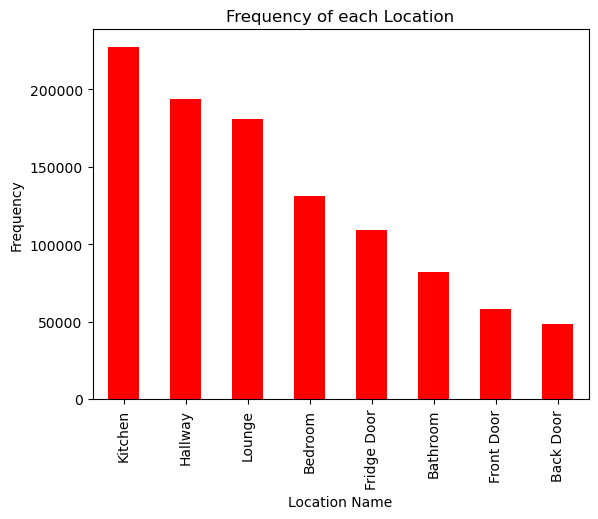

In [31]:
location_name_counts.plot(kind = 'bar', color = 'red')

plt.title('Frequency of each Location')
plt.xlabel('Location Name')
plt.ylabel('Frequency')

From the bar plot, we can see that the most ferequent location were movement was recorded by the sensors was in the kitchen and the least frequent location were movement was recorded was in the back door. However, the bar plot allows for us to see that the difference between movements captured within the sensors from different locations is minimal, especially between the Kitchen, Bedroom, Hallway, and Bathroom. The PLWD and/or other people within the home (spouse, visitors, etc.) frequented these location areas the most. 

In [32]:
activity_count_stats = activity_grouped['activity_count'].describe()
print(activity_count_stats)

count    19442.000000
mean        53.006841
std         41.583602
min          1.000000
25%         20.250000
50%         44.000000
75%         76.000000
max        314.000000
Name: activity_count, dtype: float64


Text(0.5, 1.0, 'Box Plot of Activity Count')

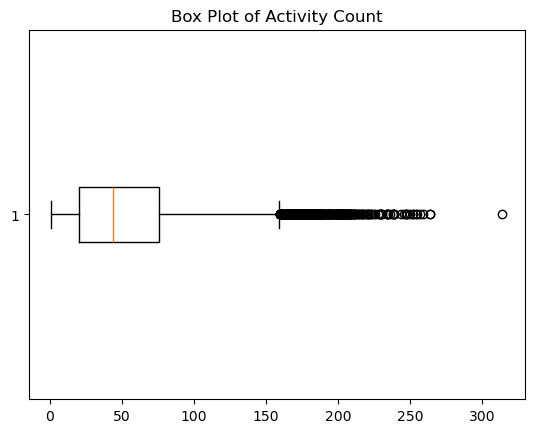

In [33]:
plt.boxplot(activity_grouped['activity_count'], vert = False)
plt.title('Box Plot of Activity Count')

The activity count within the activity_grouped table represents how frequent would each location be visited daily for each participant. The box plot shows that the average frequency each location would be visited per day. The minimum times a location would be visited was once and the maximum frequency a location would be visited was over 300 times in one day. Within the box plot, we see that the maximum value is an outlier as this frequency means that a location(s) was visited most often that others (sensors would capture movement made from PlWD  or people within the home most often). There are a bunch of trailing the end of the box plot, meaning they are outliers in which this represents that specific locations were visited more often than usual within data collection time period (300 is just the outlier that stands out the most). The data is right skewed as most of the data is to the left whereas the tail is being dragged on to the right side. 

Text(0.5, 1.0, 'Box Plot of Activity Count without Outliers')

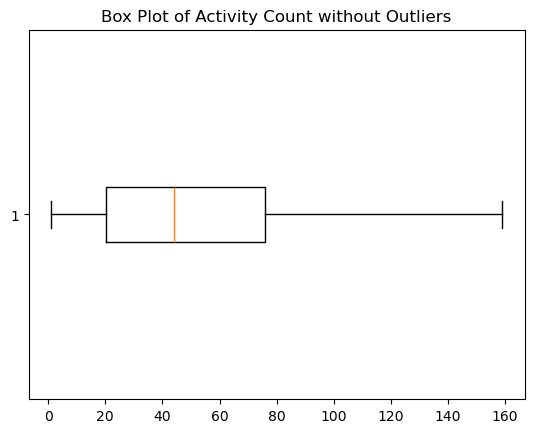

In [34]:
plt.boxplot(activity_grouped['activity_count'], vert = False, showfliers = False)
plt.title('Box Plot of Activity Count without Outliers')

This box plot represents the five number summary of activity_count variable without the outliers in which we see that the distribution of the data is still right skewed, but the range of activity_count drops significantly (from (0 - 300+) to (0 - 160)). This means that the outliers are heaviliy pushing the data to the right as the range of the outliers extends significantly (160 - 300+). It reiterates the idea that some locations were more frequented than others. 

In [35]:
sleep_grouped.dtypes

patient_id                  object
date                datetime64[ns]
heart_rate                 float64
respiratory_rate           float64
dtype: object

In [36]:
heart_rate_stats = sleep_grouped['heart_rate'].describe()
print(heart_rate_stats)

count    835.000000
mean      60.684513
std        5.887328
min       46.479691
25%       56.099285
50%       60.907692
75%       64.889231
max       77.882353
Name: heart_rate, dtype: float64


Text(0.5, 1.0, 'Box Plot of Average Heart Rate ')

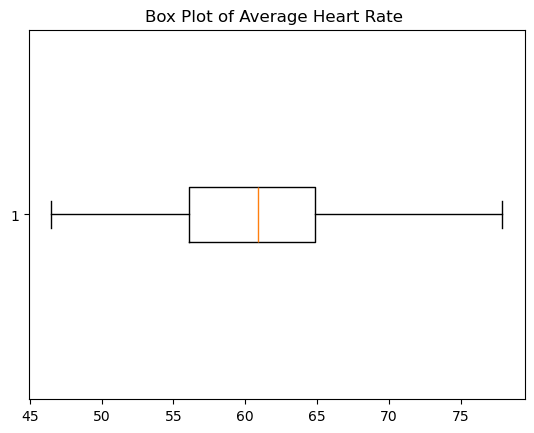

In [37]:
plt.boxplot(sleep_grouped['heart_rate'], vert = False)
plt.title('Box Plot of Average Heart Rate ')

This box plot represents the average heart rate that participants would experience daily while sleeping . The average heart rate a particpant would experience was 60 beats per minute, in which this falls right within the range of a healthy heart range for adults, which is 60-100 bpm. The minimum average heart rate that participants experienced was 45 bpm which is common for the hear rate to drop within 40 bm while sleeping (not abnormal). The maximum average heart rate participants would experience is 77 bpm, which falls within normal range. Unlike the avtivity boxplot, there are NO outliers within the sleep boxplot, meaning there were no abnormal average heart rates within the participants while they were sleeping. 

In [38]:
respiratory_rate_stats = sleep_grouped['respiratory_rate'].describe()
print(respiratory_rate_stats)

count    835.000000
mean      15.080796
std        1.626671
min       11.649194
25%       13.924752
50%       14.678947
75%       15.682249
max       20.598055
Name: respiratory_rate, dtype: float64


Text(0.5, 1.0, 'Box Plot of Average Respiratory Rate')

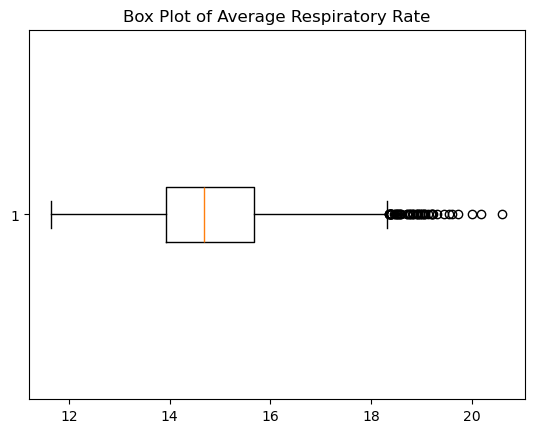

In [39]:
plt.boxplot(sleep_grouped['respiratory_rate'], vert = False)
plt.title('Box Plot of Average Respiratory Rate')

This box plot represents the average respiratory rate that the participants would experience daily while sleeping. The normal respiratory range for adults 65+ is 12 - 28 brpm. The average respiratory rate was 15 brpm, which falls under the normal range. The minimum average respiratory rate was 11 brpm, which falls slightly below the normal range and the maximum average respiratory range was 20 brpm which falls under the range. However, the box plots shows that there are multiple outliers, yet these fall under the normal range. 

Text(0.5, 1.0, 'Box Plot of Average Respiratory Rate')

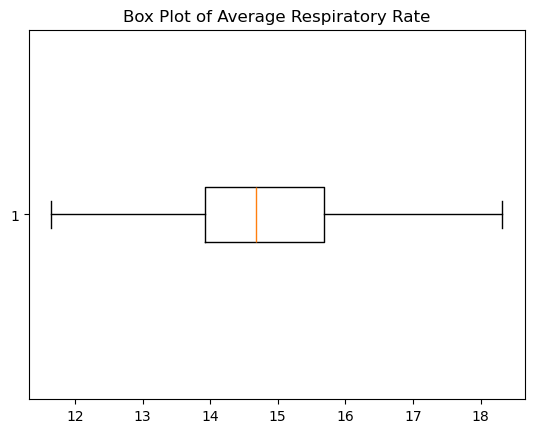

In [40]:
plt.boxplot(sleep_grouped['respiratory_rate'], vert = False, showfliers = False)
plt.title('Box Plot of Average Respiratory Rate')

This boxplot demonstrates the average respiratory rate of particpants without the outliers, in which the range still falls within normal ranges.

In [41]:
physiology_grouped.dtypes

patient_id             object
date           datetime64[ns]
device_type            object
value                 float64
dtype: object

In [42]:
import seaborn as sns

In [43]:
body_temp_data = physiology_grouped[physiology_grouped['device_type'] == 'Body Temperature']
body_weight_data = physiology_grouped[physiology_grouped['device_type'] == 'Body weight']
dbp_data = physiology_grouped[physiology_grouped['device_type'] == 'Diastolic blood pressure']
heart_rate_data = physiology_grouped[physiology_grouped['device_type'] == 'Heart rate']
musclemass_data = physiology_grouped[physiology_grouped['device_type'] == 'O/E - muscle mass']
sbp_data = physiology_grouped[physiology_grouped['device_type'] == 'Systolic blood pressure']
totwater_data = physiology_grouped[physiology_grouped['device_type'] == 'Total body water']
skintemp_data = physiology_grouped[physiology_grouped['device_type'] == 'Skin Temperature']

Text(0, 0.5, 'Values')

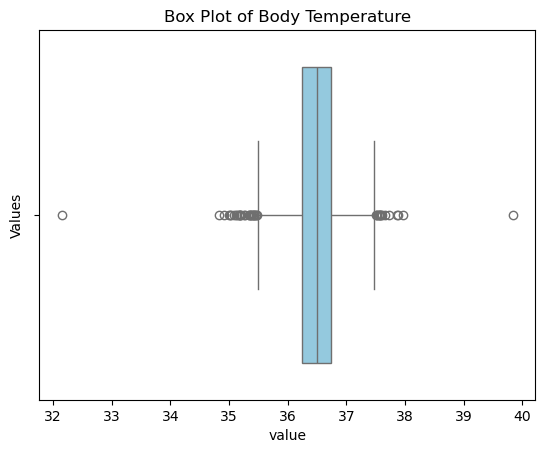

In [44]:
sns.boxplot(x='value', data=body_temp_data, color='skyblue')
plt.title('Box Plot of Body Temperature')
plt.ylabel('Values')

This boxplot shows the average body temperature that a participant would record daily. The normal range of body temperature for an adult is to be between 36 - 37 degrees Celcius (97 - 99 degrees Farenheit). The box plot shows that there is an outlier on both extremes, in which the minimum average body temperature a participant recorded for a specifc day was 32 degrees Celcius and the maximum average body temperature a participant recorded was 40 degrees Celcius. We need to understand why the participants recorded these extreme body temperatures. However, there also exist other outliers in which they do not fall within the normal range for body temperature. The median average body temperature recorded was around 36.5 degrees Celcius which is within range. 

Text(0, 0.5, 'Values')

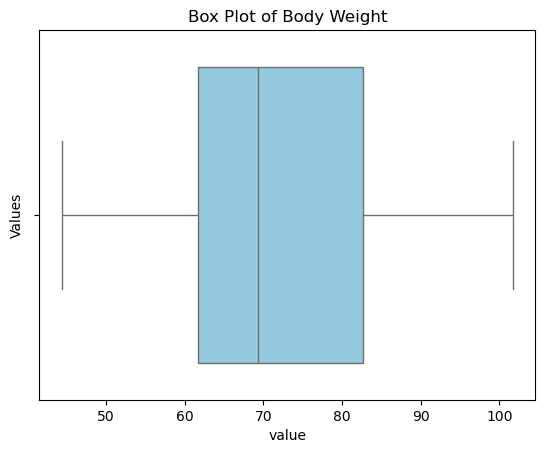

In [45]:
sns.boxplot(x='value', data=body_weight_data, color='skyblue')
plt.title('Box Plot of Body Weight')
plt.ylabel('Values')

This boxplot shows the average body weight that a participant would record daily. Body weight is a metric that vary depending on nutrition, genetics, and other factors so it is difficult to classifiy someone as healthy based only on body weight. The global average body weight for males is around 62 - 90 kg for males and 52 - 78 kg for females. The box plot demonstrates no outliers, meaning there was no abnormal body weight that was recorded on a given day. The box plot shows the median body weight is 70 kg which falls within the ranges for males and females. There seems to be a difference between Q1 and Q3, in which could possibly be due to the difference in weight ranges between males and females (needs to be investigated more)

Text(0, 0.5, 'Values')

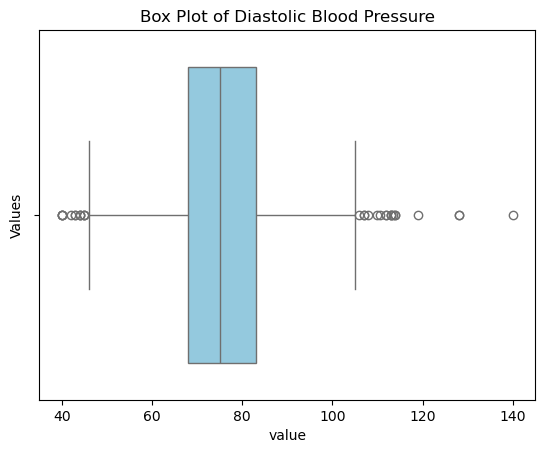

In [46]:
sns.boxplot(x='value', data=dbp_data, color='skyblue')
plt.title('Box Plot of Diastolic Blood Pressure')
plt.ylabel('Values')

This box plot demonstrates the average Diastolic Blood Pressure that was recorded daily. Diastolic blood pressure measures the pressure in the arteries when the heart is resting. The normal range for diastolic blood pressure is for it to fall less than 80 mm Hg. According to the box plot, there seems to be outliers on both extremes, in which the diastolic blood pressure fell within the range between 40 - 50 mm Hg and rose between 100 - 140 mm Hg. Along with the systolic blood pressure, these outliers need to be investigated to determine if the particpants experience low or elevated blood pressure. The median average diastolic blood pressure that was recorded is around 75 mm Hg, which falls within the healthy range. The minimum average diastolic blood pressure that was recorded within a given day was around 50 mm Hg and the maximum average diastolic blood pressure that was recorded was 140 mm Hg (which is really high - possible hypertension?)

Text(0, 0.5, 'Values')

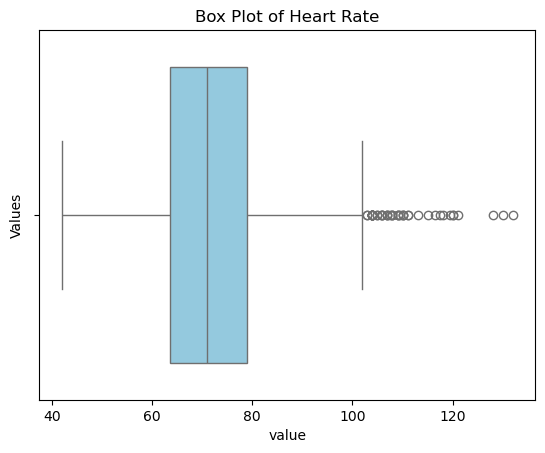

In [47]:
sns.boxplot(x='value', data= heart_rate_data, color='skyblue')
plt.title('Box Plot of Heart Rate')
plt.ylabel('Values')

This box plot demonstrates the average heart rate that was recorded from participants daily. The normal heart range for adults falls between 60 -100 bpm. There exists outliers within the boxplot, in which some participants experienced abnormal heart rate, which ranges from 100 bpm +, in which we need to investigate is certain particpants experience certain heart conditions that could cause there heart rates to rise significantly. The avergae heart rate recorded within a given day sits between 70 bpm which falls within the healthy range. The minimum avergae heart rate that was recorded was 40 bpm (low) and the maximum heart rate that was recorded is 120+ bpm(high). 

Text(0, 0.5, 'Values')

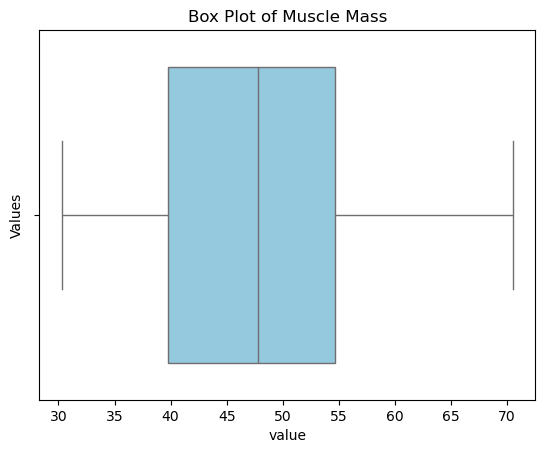

In [48]:
sns.boxplot(x='value', data= musclemass_data, color='skyblue')
plt.title('Box Plot of Muscle Mass')
plt.ylabel('Values')

This boxplot represents the average muscle mass that was recorded for a participant daily. Muscle mass is dependent on total body weight and varies between genders as well as age. We need to determine for the participants if the muscle mass is healthy based on thier body weight. 

Text(0, 0.5, 'Values')

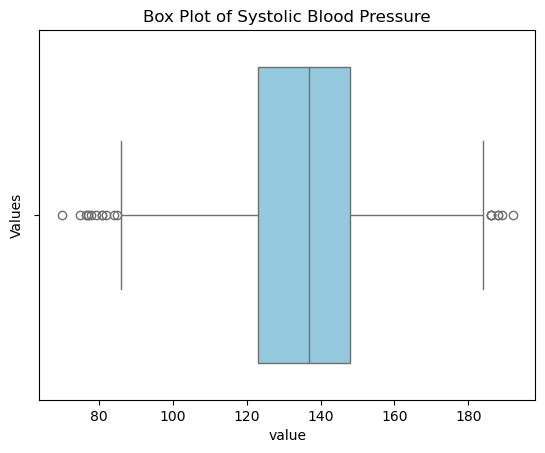

In [49]:
sns.boxplot(x='value', data=sbp_data, color='skyblue')
plt.title('Box Plot of Systolic Blood Pressure')
plt.ylabel('Values')

This boxplot shows the average systolic blood pressure that was measured daily by participants. THe normal systolic blood pressure for adults is for it to be less than 120 mm Hg. There exists outliers on both extremes, in which the systolic blood pressure fell less than 90 mm Hg and was higher than 180 mm Hg. Like previously said, we need to investigate if the participants suffer from conditions that could be cause for low or high blood pressure in accordance to their systolic bloof pressure as well. The median average systolic blood pressure that was recorded on a day was close to 140 mm Hg which is elevated compared to the normal range of less than 120 mm Hg. The minimum average systolic blood pressure that was taken was around 60 mm Hg (low -> what is causing blood pressure to be this low?) and the maximum average systolic blood pressure that was taken was around 180+ mm Hg (what is causing blood pressure to be this high? is it the environment? medical condition? -> needs to be investigated further?). 

Text(0, 0.5, 'Values')

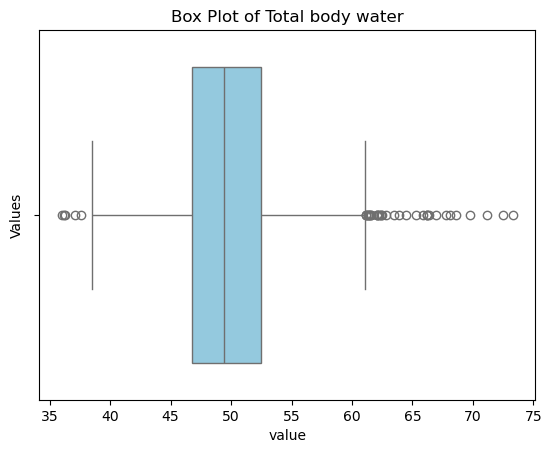

In [50]:
sns.boxplot(x='value', data=totwater_data, color='skyblue')
plt.title('Box Plot of Total body water')
plt.ylabel('Values')

This box plot shows the average total body water that a participant recorded daily. Body temperature, just like muscle mass, is dependent on total body weight. Like stated before, body weight is dependent on a lot of factors, in which gender, genetics, nutrition, exercise, as well as other factors play a role. There exists multiple outliers, in which this could be due to the different weight ranges between males and females but this needs to be investigated more in detail. 

Text(0, 0.5, 'Values')

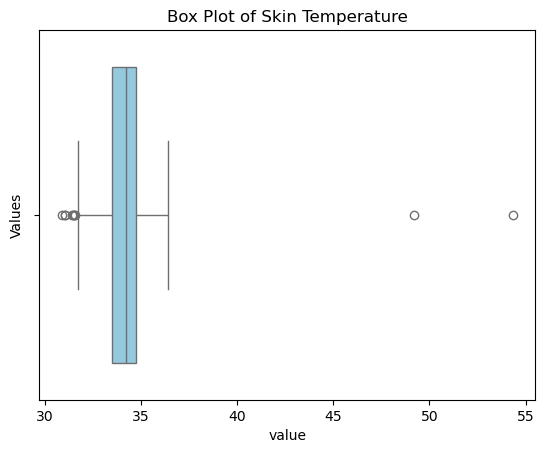

In [51]:
sns.boxplot(x='value', data=skintemp_data, color='skyblue')
plt.title('Box Plot of Skin Temperature')
plt.ylabel('Values')

This box plot demonstartes the average skin temperature that was recorded daily by participants. The normal range of skin temperature falls between 33 - 36 degrees celsius. There exists outliers on both extremes in which skin temperature was recorded below 35 degrees celsius in which some of the outliers seem to safely fall within the normal range of skin temperature. However, for the other extreme, there are two outliers that stand out in which on one day, one participant recorded a skin temperature close to 50 degrees Celsius and another one (or maybe even same one) recorded a skin temperature close to 55 degrees Celsius. These high skin temperatures need to be investigated, i.e. what is causing them to have skin temperatures this high, could be malfunction of recording device? human error?. The average skin temperature that was recorded was around 34 degress Celsius which falls within normal range. 

Possible Next Steps:
- We can possibly research how changes within the environment, sleep, or vital signs can help catch an alert and be used as early detection before it escalates into something more serious. We can investigate and look into the PLWD's environment, vital signs, and sleep habits prior to an alert being raised to see if any patterns were occuring that could identify these issues much quicker. For example, we can look at data from the physiology table to see if any abnormal changes happened 3-7 days prior to alert being raised. We can also join the activity, sleep, and physiology data with corresponding labels to see what specifc measurements could possibly have caused alerts to be raised.